In [1]:
import qutip as qt
import matplotlib.pyplot as plt
import numpy as np

from IPython.display import display

Define number of atoms in the ensemble and the Fock-state cutoffs for the Stokes photon number (ns) and the anti-Stokes photon number (nas).

In [2]:
atom_number = 2

ns_cutoff = 2
nas_cutoff = 2

In [3]:
# define Gamma_s and Gamma_as

def calc_effective_transition_rates(Omega_p, Omega_c, Delta_p, Delta_c, g_s, g_as, kappa_s, kappa_as):
    
    # Stark shifts of both ground state per atom
    delta_g = atom_number * Omega_p**2 / (4 * Delta_p)
    delta_e = g_s**2 / Delta_p
    
    # effective Stokes rate
    Gamma_s = atom_number * g_s**2 * Omega_p**2 / (16 * kappa_s * Delta_p**2)
    
    # effective anti-Stokes rate
    A_square = (Gamma_s + kappa_as)**2 + 4 * (Delta_c - delta_g)**2
    
    X = (Gamma_s + kappa_as)**2 - 4 * (Delta_c - delta_g) * (delta_e - delta_g) + Omega_c**2
    Y = 2 * (Gamma_s + kappa_as) * (Delta_c + delta_e - 2 * delta_g)
    
    nom_c1 = Omega_c**2 * g_as**2 * (Gamma_s + kappa_as) * (A_square + Omega_c**2)
    nom_c2 = 4 * Omega_c**2 * g_as**2 * (Gamma_s + kappa_as) * ((Delta_c - delta_g)**2 - (delta_e - delta_g)**2 + g_as**2)

    term1 = ((Delta_c - delta_e) * X - 4 * (Delta_c - delta_g) * g_as**2)**2
    term2 = ((Delta_c - delta_e) * Y + 2 * (Gamma_s + kappa_as) * g_as**2)**2
    denom = term1 + term2

    c1 = nom_c1 / denom
    c2 = nom_c2 / denom

    Gamma_as = c1
    
    return Gamma_s, Gamma_as

In [4]:
states = [qt.basis(4, i) for i in range(4)]

# atom basis states
state1 = states[0]
state2 = states[1]
state3 = states[2]
state4 = states[3]

# fock basis states
basis_s = qt.fock(ns_cutoff, 0)
basis_as = qt.fock(nas_cutoff, 0)

# identity operators
I_atom = qt.qeye(4)
I_s = qt.qeye(ns_cutoff)
I_as = qt.qeye(nas_cutoff)
I = qt.tensor([I_atom] * atom_number + [I_s, I_as])

# function to build operators in total collective atomic Hilbert space
def atom_operator(op, atom, N):
    operators = []
    
    for i in range(N):
        if i == atom:
            operators.append(op)
        else:
            operators.append(I_atom)
            
    operators.append(I_s)
    operators.append(I_as)
    
    return qt.tensor(operators)

In [5]:
# single atom transition operators

sigma_11_local = qt.projection(4, 0, 0)
sigma_22_local = qt.projection(4, 1, 1)
sigma_33_local = qt.projection(4, 2, 2)
sigma_44_local = qt.projection(4, 3, 3)

sigma_12_local = qt.projection(4, 0, 1)
sigma_21_local = sigma_12_local.dag() 

sigma_14_local = qt.projection(4, 0, 3)
sigma_41_local = sigma_14_local.dag()

sigma_24_local = qt.projection(4, 1, 3)
sigma_42_local = sigma_24_local.dag()

sigma_23_local = qt.projection(4, 1, 2)
sigma_32_local = sigma_23_local.dag()

sigma_13_local = qt.projection(4, 0, 2)
sigma_31_local = sigma_13_local.dag()

In [6]:
# collective operators

sigma_11 = []
sigma_22 = []
sigma_33 = []
sigma_44 = []

sigma_12 = []
sigma_21 = []

sigma_14 = []
sigma_41 = []

sigma_24 = []
sigma_42 = []

sigma_23 = []
sigma_32 = []

sigma_13 = []
sigma_31 = []

# define operators in the N-particle atomic Hilbert space
for i in range(atom_number):
    sigma_11.append(atom_operator(sigma_11_local, i, atom_number))
    sigma_22.append(atom_operator(sigma_22_local, i, atom_number))
    sigma_33.append(atom_operator(sigma_33_local, i, atom_number))
    sigma_44.append(atom_operator(sigma_44_local, i, atom_number))
    
    sigma_12.append(atom_operator(sigma_12_local, i, atom_number))
    sigma_21.append(atom_operator(sigma_21_local, i, atom_number))
    
    sigma_14.append(atom_operator(sigma_14_local, i, atom_number))
    sigma_41.append(atom_operator(sigma_41_local, i, atom_number))
    
    sigma_24.append(atom_operator(sigma_24_local, i, atom_number))
    sigma_42.append(atom_operator(sigma_42_local, i, atom_number))
    
    sigma_23.append(atom_operator(sigma_23_local, i, atom_number))
    sigma_32.append(atom_operator(sigma_32_local, i, atom_number))
    
    sigma_13.append(atom_operator(sigma_13_local, i, atom_number))
    sigma_31.append(atom_operator(sigma_31_local, i, atom_number))

# define the collective operators
Sigma_11 = sum(sigma_11)
Sigma_22 = sum(sigma_22)
Sigma_33 = sum(sigma_33)
Sigma_44 = sum(sigma_44)

Sigma_12 = sum(sigma_12)
Sigma_21 = sum(sigma_21)

Sigma_14 = sum(sigma_14)
Sigma_41 = sum(sigma_41)

Sigma_24 = sum(sigma_24)
Sigma_42 = sum(sigma_42)

Sigma_23 = sum(sigma_23)
Sigma_32 = sum(sigma_32)

Sigma_13 = sum(sigma_13)
Sigma_31 = sum(sigma_31)

In [7]:
# define the bosonic operators in the total Hilbert space

a_s = qt.tensor([I_atom for _ in range(atom_number)] + [qt.destroy(ns_cutoff), I_as])
a_s_dag = a_s.dag()
a_as = qt.tensor([I_atom for _ in range(atom_number)] + [I_s, qt.destroy(nas_cutoff)])
a_as_dag = a_as.dag()

Ns = a_s_dag * a_s
Nas = a_as_dag * a_as

In [8]:
# total state information and initial state

print("State definition: |Atom, Stokes, anti-Stokes>")
print("State definition: |Atom_1, ..., Atom_N, Stokes, anti-Stokes>")
print(f"Full Hilbert-space dimensions: {I.shape}")
print(f"Total Hilbert-space dimension: {I.shape[0]}")
# initial state
psi_atoms = [qt.basis(4, 0) for _ in range(atom_number)]
psi_s    = qt.fock(ns_cutoff, 0)
psi_as   = qt.fock(nas_cutoff, 0)

psi0 = qt.tensor(psi_atoms + [psi_s, psi_as])

State definition: |Atom, Stokes, anti-Stokes>
State definition: |Atom_1, ..., Atom_N, Stokes, anti-Stokes>
Full Hilbert-space dimensions: (64, 64)
Total Hilbert-space dimension: 64


In [9]:
# Hamiltonian

def get_Hamiltonian(Delta_p, Delta_c, Omega_p, Omega_c, g_s, g_as):
    
    H_atom = Delta_c * Sigma_33 + Delta_p * Sigma_44
    H_int = (Omega_p/2) * (Sigma_14 + Sigma_41) + g_s * (a_s_dag * Sigma_24 + a_s * Sigma_42) \
        + (Omega_c/2) * (Sigma_23 + Sigma_32) + g_as * (a_as_dag * Sigma_13 + a_as * Sigma_31) 
        
    return H_atom + H_int

In [10]:
# collapse operators for master equation

def collapse_operator_list(kappa_s, kappa_as, Gamma_41=None, Gamma_42=None, 
                           Gamma_31=None, Gamma_32=None, Gamma_d=None):

    c_ops = []

    c_ops.append(np.sqrt(kappa_s) * a_s)
    c_ops.append(np.sqrt(kappa_as) * a_as)
    
    c_ops.append(np.sqrt(Gamma_41) * Sigma_41) if Gamma_41 is not None else None
    c_ops.append(np.sqrt(Gamma_42) * Sigma_42) if Gamma_42 is not None else None
    c_ops.append(np.sqrt(Gamma_31) * Sigma_31) if Gamma_31 is not None else None
    c_ops.append(np.sqrt(Gamma_32) * Sigma_32) if Gamma_32 is not None else None
    c_ops.append(np.sqrt(Gamma_d) * (Sigma_11 - Sigma_22)/2) if Gamma_d is not None else None
    
    return c_ops
    

In [11]:
# solve the master equation

def solve_master_equation(Omega_p, Omega_c, Delta_p, Delta_c, g_s, g_as, kappa_s, kappa_as,
                          Gamma_41=None, Gamma_42=None, Gamma_31=None, Gamma_32=None, 
                          Gamma_d=None, solver=None):
    
    # expectation values
    e_ops = [Sigma_44, Sigma_33, Sigma_22, Sigma_11, Ns, Nas]
    
    # Hamiltonian and collapse operators
    H = get_Hamiltonian(Delta_p, Delta_c, Omega_p, Omega_c, g_s, g_as)
    c_ops = collapse_operator_list(kappa_s, kappa_as, Gamma_41, Gamma_42, Gamma_31, Gamma_32, Gamma_d)
    
    t_list = np.linspace(0, 1500, 1000)
    
    if solver is None:
        data = qt.mcsolve(H, psi0, t_list, c_ops=c_ops, e_ops=e_ops, ntraj=1500)
    else:
        data = qt.mesolve(H, psi0, t_list, c_ops=c_ops, e_ops=e_ops)
        
    return t_list, data

In [12]:
# numerics with data and plotting

def plot_solution(Omega_p, Omega_c, Delta_p, Delta_c, g_s, g_as, kappa_s, kappa_as,
                            Gamma_41=None, Gamma_42=None, Gamma_31=None, Gamma_32=None, 
                            Gamma_d=None, solver="exact"):

    t_list, data = solve_master_equation(Omega_p=Omega_p, Omega_c=Omega_c, Delta_p=Delta_p,
                                 Delta_c=Delta_c, g_s=g_s, g_as=g_as, kappa_s=kappa_s, kappa_as=kappa_as,
                                 Gamma_41=Gamma_41, Gamma_42=Gamma_42, Gamma_31=Gamma_31,
                                 Gamma_32=Gamma_32, Gamma_d=Gamma_d, solver=solver)

    pop4_expect = data.expect[0]
    pop3_expect = data.expect[1]
    pop2_expect = data.expect[2]
    pop1_expect = data.expect[3]
    populations = [pop1_expect, pop2_expect, pop3_expect, pop4_expect]

    Ns_expect = data.expect[4]
    Nas_expect = data.expect[5]

    max_ns = max(Ns_expect)
    max_nas = max(Nas_expect)
    
    # plot the populations
    
    plt.figure(figsize=(6, 4))

    plt.rcParams['text.usetex'] = True

    for i, population in enumerate(populations, start=1):
        plt.plot(t_list, population, label=fr'$\langle S_{{{i}{i}}}\rangle$')
        
    plt.title("Population")
    plt.xlabel(r'$\Gamma t$')
    plt.ylabel(r'$\langle\Sigma_{ii}\rangle$')
    plt.legend(loc='upper right')
    plt.grid(True)

    # plot the photon numbers
    
    plt.figure(figsize=(6, 4))

    photon_number = [(Ns_expect, "Stokes"), (Nas_expect, "anti-Stokes")]

    for expectation, label in photon_number:
        plt.plot(t_list, expectation, label=label)

    plt.title("Photon Number")
    plt.xlabel(fr'$\Gamma t$')
    plt.ylabel(r'$\langle N\rangle$')
    plt.legend(loc="upper right")
    plt.grid(True)

    plt.show()


'$\\Gamma__\\text{s}$: 0.00028125'

'$\\Gamma__\\text{as}$: 0.0022500835059066737'

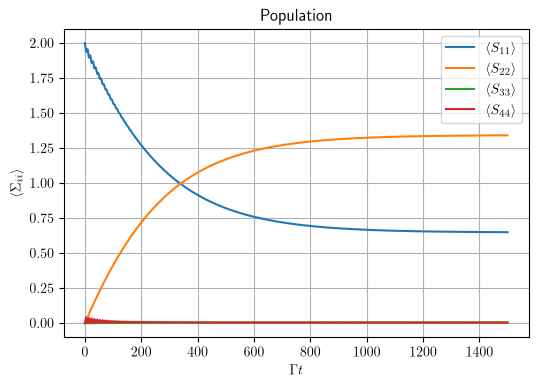

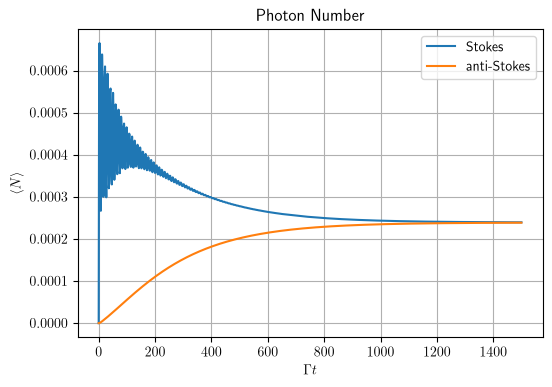

In [13]:
Gamma = 1
Omega_p = 3 * Gamma
Omega_c = 0.03 * Gamma
g_s = 1 * Gamma
g_as = 1 * Gamma
Delta_p = 20 * Gamma
Delta_c = g_s**2 / Delta_p
kappa_s = 10 * Gamma
kappa_as = 10 * Gamma

Gamma_s, Gamma_as = calc_effective_transition_rates(Omega_p, Omega_c, Delta_p, Delta_c, g_s, g_as, kappa_s, kappa_as)
display(rf"$\Gamma__\text{{s}}$: {Gamma_s}")
display(rf"$\Gamma__\text{{as}}$: {Gamma_as}")

plot_solution(Omega_p, Omega_c, Delta_p, Delta_c, g_s, g_as, kappa_s, kappa_as,
                            Gamma_41=None, Gamma_42=None, Gamma_31=None, Gamma_32=None, 
                            Gamma_d=None, solver="exact")